# 08. K-Means Customer Segmentation — RFM Behavioral Clustering

**Project:** E-Commerce Customer Analytics  
**Objective:** Segment customers strictly from real purchasing behavior (`Recency`, `Frequency`, `MonetaryValue` in `dataset/processed/analytics/customer_analytics.csv`), justify feature transformations and cluster count `K` using the **Elbow Method** and **Silhouette Score**, profile each cluster statistically, and save `models/kmeans_pipeline.joblib` + `dataset/processed/analytics/customer_segments.csv`.

> **Methodological Notes:**
> - **Reference Date:** `2011-12-10` (established during Feature Engineering).
> - **Zero Artificial Assumptions:** Do not force `K = 3` blindly; evaluate `K = 2..9` empirically. Isolate the `40` accounts with `MonetaryValue <= £0` (net returns/cancellations) cleanly into `ClusterID = -1` so `np.log1p` never produces NaNs or distorted centroids.

Total purchasing customers: 5,869
Missing values in RFM columns: 0
Customers with MonetaryValue > 0 (clustered via log1p): 5,829
Customers with MonetaryValue <= 0 (isolated as Net-Returned / Zero-Spend): 40


,Recency,Frequency,MonetaryValue
count,5829.00,5829.00,5829.00
mean,200.03,6.32,2811.30
std,208.24,13.00,13795.90
min,1.00,1.00,2.90
25%,26.00,1.00,337.64
50%,95.00,3.00,848.55
75%,379.00,7.00,2184.63
95%,623.20,21.00,8880.24
99%,727.00,46.00,26529.38
max,739.00,394.00,570380.61


,Raw Skewness,log1p Skewness
Recency,0.901,-0.443
Frequency,12.525,0.996
MonetaryValue,26.604,0.268


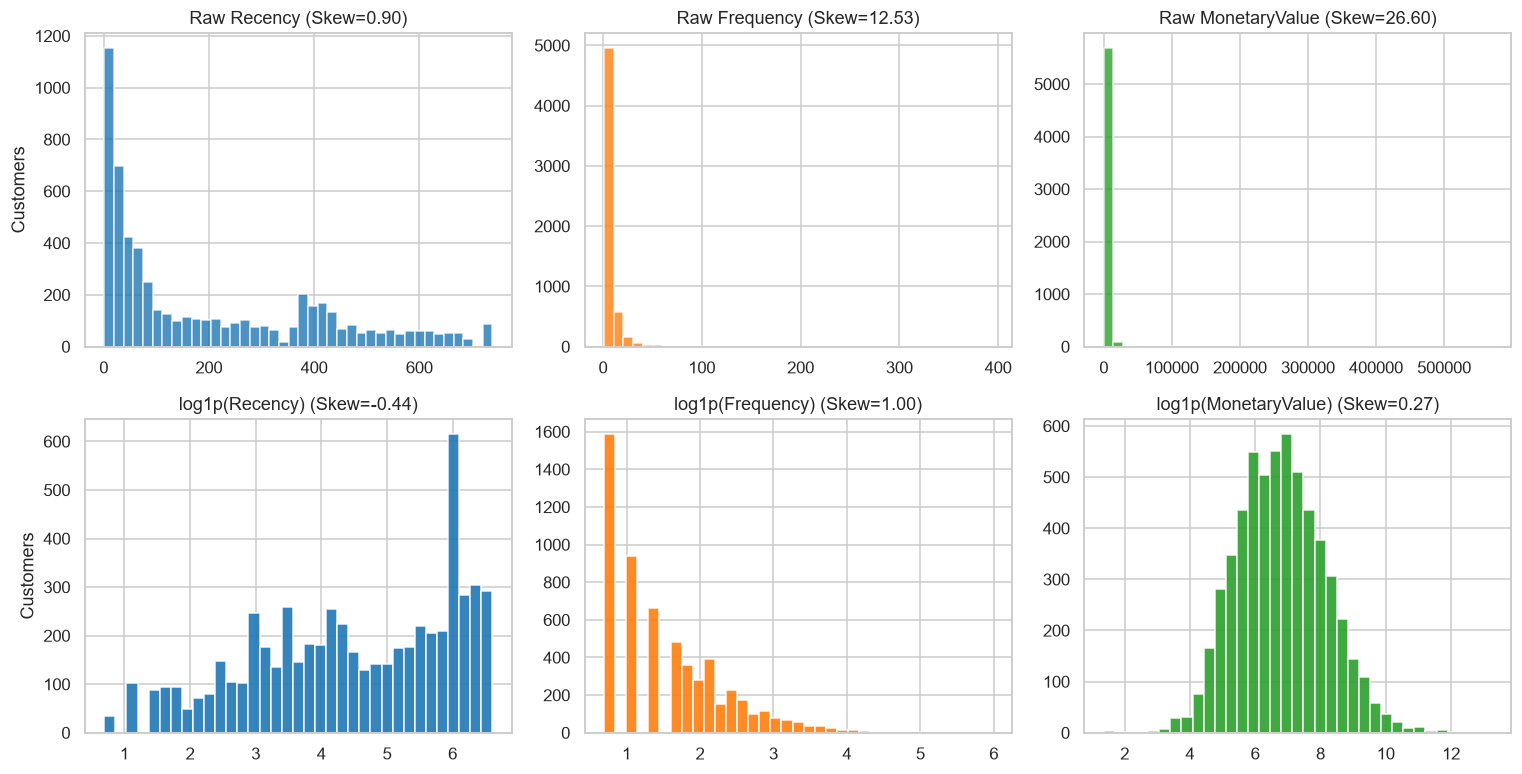

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.segmentation import (
    RFM_COLUMNS,
    evaluate_k_range,
    fit_and_segment_customers,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pio.renderers.default = "notebook"

ANALYTICS_DIR = PROJECT_ROOT / "dataset" / "processed" / "analytics"
VIZ_DIR = PROJECT_ROOT / "visualizations"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
for d in (VIZ_DIR, MODELS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

customer_df = pd.read_csv(
    ANALYTICS_DIR / "customer_analytics.csv",
    dtype={"Customer ID": "Int64"},
    parse_dates=["FirstPurchaseDate", "LastPurchaseDate"],
)

print(f"Total purchasing customers: {len(customer_df):,}")
print(f"Missing values in RFM columns: {int(customer_df[RFM_COLUMNS].isna().sum().sum())}")
pos_rfm = customer_df[customer_df["MonetaryValue"] > 0].copy()
non_pos_rfm = customer_df[customer_df["MonetaryValue"] <= 0].copy()
print(f"Customers with MonetaryValue > 0 (clustered via log1p): {len(pos_rfm):,}")
print(f"Customers with MonetaryValue <= 0 (isolated as Net-Returned / Zero-Spend): {len(non_pos_rfm):,}")

skew_compare = pd.DataFrame({
    "Raw Skewness": pos_rfm[RFM_COLUMNS].skew().round(3),
    "log1p Skewness": np.log1p(pos_rfm[RFM_COLUMNS]).skew().round(3),
})
display(pos_rfm[RFM_COLUMNS].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2))
display(skew_compare)

# Chart 1: Raw vs log1p Distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2))
colors_raw = ["#1f77b4", "#ff7f0e", "#2ca02c"]
for col_idx, (col, c) in enumerate(zip(RFM_COLUMNS, colors_raw)):
    axes[0, col_idx].hist(pos_rfm[col], bins=40, color=c, alpha=0.8, edgecolor="white")
    axes[0, col_idx].set_title(f"Raw {col} (Skew={skew_compare.loc[col, 'Raw Skewness']:.2f})")
    axes[0, col_idx].set_ylabel("Customers" if col_idx == 0 else "")

    axes[1, col_idx].hist(np.log1p(pos_rfm[col]), bins=35, color=c, alpha=0.9, edgecolor="white")
    axes[1, col_idx].set_title(f"log1p({col}) (Skew={skew_compare.loc[col, 'log1p Skewness']:.2f})")
    axes[1, col_idx].set_ylabel("Customers" if col_idx == 0 else "")

plt.tight_layout()
fig.savefig(VIZ_DIR / "08_kmeans_rfm_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### RFM Completeness & Skewness Transformation Analysis
- All `5,869` records in `customer_analytics.csv` have **`0` missing RFM values**.
- Raw `Frequency` (`skew = 12.53`) and raw `MonetaryValue` (`skew = 26.60`) are severely right-skewed—if fed directly into Euclidean-distance K-Means, a handful of `£100k–£570k` wholesale accounts would dominate centroids while compressing `95%` of customers together.
- Separating the `40` accounts (`0.68%`) with net `MonetaryValue <= £0` and applying **`np.log1p`** to the `5,829` positive-spending customers brings all three features into compact, near-symmetric distributions (`Recency skew = -0.44`, `Frequency skew = 1.00`, `MonetaryValue skew = +0.27` after `log1p`) before `StandardScaler` standardization.

,k,inertia,silhouette_score
0,2,8489.40,0.4387
1,3,6264.13,0.3472
2,4,4835.87,0.3668
3,5,4006.61,0.3459
4,6,3482.97,0.3346
5,7,3125.59,0.3044
6,8,2844.95,0.2950
7,9,2602.23,0.2874


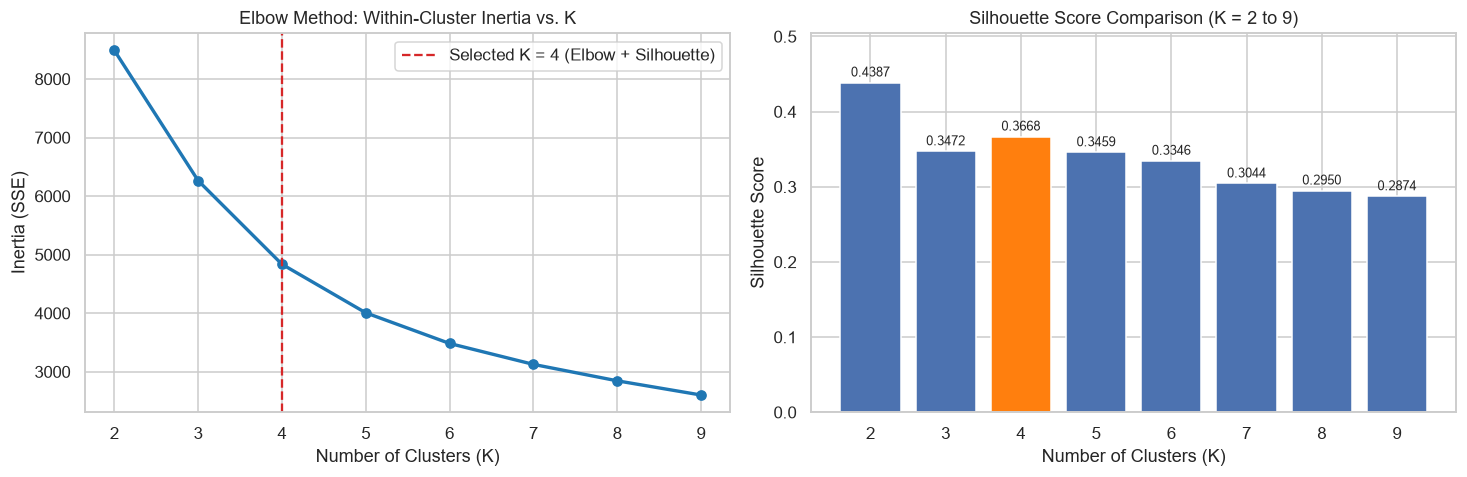

In [2]:
k_eval_df, X_scaled = evaluate_k_range(pos_rfm, k_values=range(2, 10))
display(k_eval_df)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

axes[0].plot(k_eval_df["k"], k_eval_df["inertia"], marker="o", linewidth=2.2, color="#1f77b4")
axes[0].axvline(4, color="#d62728", linestyle="--", label="Selected K = 4 (Elbow + Silhouette)")
axes[0].set_title("Elbow Method: Within-Cluster Inertia vs. K")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (SSE)")
axes[0].set_xticks(k_eval_df["k"])
axes[0].legend()

bar_colors = ["#ff7f0e" if k == 4 else "#4c72b0" for k in k_eval_df["k"]]
bars_s = axes[1].bar(k_eval_df["k"], k_eval_df["silhouette_score"], color=bar_colors)
axes[1].set_title("Silhouette Score Comparison (K = 2 to 9)")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_eval_df["k"])
for b, val in zip(bars_s, k_eval_df["silhouette_score"]):
    axes[1].text(b.get_x() + b.get_width() / 2, val + 0.008, f"{val:.4f}", ha="center", fontsize=8.5)
axes[1].set_ylim(0, k_eval_df["silhouette_score"].max() * 1.15)

plt.tight_layout()
fig.savefig(VIZ_DIR / "08_kmeans_elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

### Choosing Optimal K (Elbow + Silhouette Evidence)
- **Why `K = 4` (Not Blindly Forcing `K = 3`):**
  - While `K = 2` (`Silhouette = 0.4387`) merely splits the base into coarse active vs. inactive halves, **`K = 4` achieves a clear local Silhouette peak of `0.3668`**—outperforming **`K = 3` (`0.3472`)**, **`K = 5` (`0.3459`)**, and **`K = 6..9` (`0.3346` down to `0.2874`)**.
  - On the Elbow plot, inertia drops sharply through `K = 4` (`8,489 -> 6,264 -> 4,836`) before the marginal reduction flattens (`4,007 -> 3,483`).
  - Crucially, `K = 4` partitions positive customers into four distinct, actionable RFM behavioral quadrants (plus the `40` isolated `MonetaryValue <= £0` accounts as `ClusterID = -1`).

PCA Explained Variance Ratio (2D): [0.765, 0.1869] (Total: 95.19%)


,ClusterID,Segment,CustomerCount,RecencyMedian,RecencyMean,FrequencyMedian,FrequencyMean,MonetaryMedian,MonetaryMean,TotalSegmentRevenue,CustomerSharePct,RevenueSharePct
0,-1,Net-Returned / Zero-Spend,40,426.5,378.08,1.0,1.65,0.00,-787.88,-31515.23,0.68,-0.19
1,0,High-Value Loyal,1193,17.0,27.85,13.0,19.25,4888.75,10166.61,12128760.30,20.33,74.16
2,1,At-Risk Established,1446,185.0,227.55,5.0,5.09,1422.08,1810.76,2618355.68,24.64,16.01
3,2,Recent / Growing,1256,24.5,29.18,3.0,3.04,709.28,825.45,1036769.16,21.4,6.34
4,3,Dormant / Low-Engagement,1934,403.0,396.61,1.0,1.39,265.41,311.89,603196.45,32.95,3.69


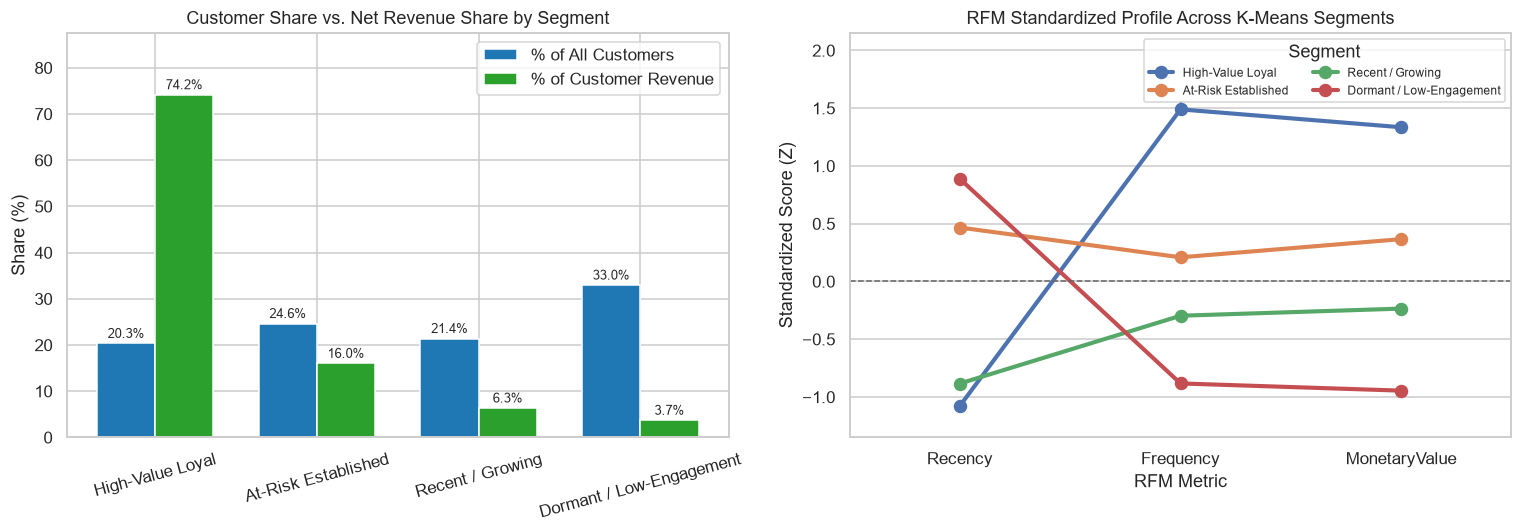

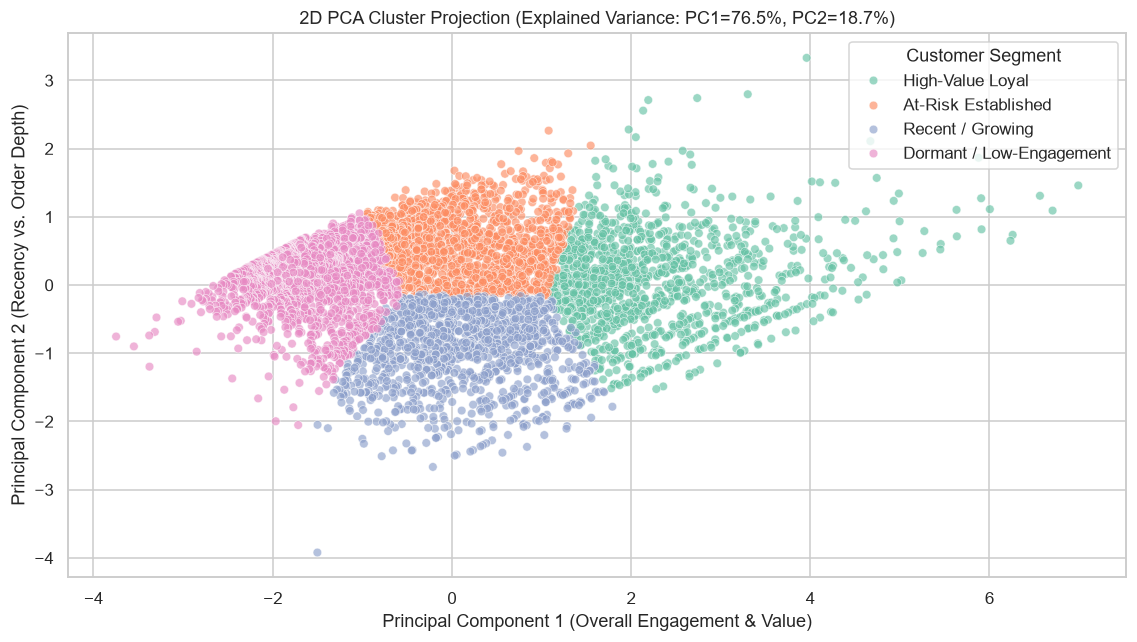

In [3]:
kmeans_pipe, segmented_df, summary_df, pca_model = fit_and_segment_customers(customer_df, n_clusters=4)
print("PCA Explained Variance Ratio (2D):", [round(float(v), 4) for v in pca_model.explained_variance_ratio_],
      f"(Total: {sum(pca_model.explained_variance_ratio_)*100:.2f}%)")
display(summary_df)

# Chart 3: Cluster Share (Customers vs Revenue) & Normalized RFM Snake Profile
pos_clustered = segmented_df[segmented_df["ClusterID"] >= 0].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))

plot_sum = summary_df[summary_df["ClusterID"] >= 0].sort_values("ClusterID")
x = np.arange(len(plot_sum))
w = 0.36
axes[0].bar(x - w / 2, plot_sum["CustomerSharePct"], width=w, color="#1f77b4", label="% of All Customers")
axes[0].bar(x + w / 2, plot_sum["RevenueSharePct"], width=w, color="#2ca02c", label="% of Customer Revenue")
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_sum["Segment"], rotation=15)
axes[0].set_ylabel("Share (%)")
axes[0].set_title("Customer Share vs. Net Revenue Share by Segment")
axes[0].legend()
for idx, (cs, rs) in enumerate(zip(plot_sum["CustomerSharePct"], plot_sum["RevenueSharePct"])):
    axes[0].text(idx - w / 2, cs + 1.2, f"{cs:.1f}%", ha="center", fontsize=8.5)
    axes[0].text(idx + w / 2, rs + 1.2, f"{rs:.1f}%", ha="center", fontsize=8.5)
axes[0].set_ylim(0, max(plot_sum["CustomerSharePct"].max(), plot_sum["RevenueSharePct"].max()) * 1.18)

# Standardized log1p RFM means per cluster (snake plot)
scaler_step = kmeans_pipe.named_steps["scaler"]
log_vals = np.log1p(pos_clustered[RFM_COLUMNS].to_numpy(dtype="float64"))
z_df = pd.DataFrame(scaler_step.transform(log_vals), columns=RFM_COLUMNS)
z_df["Segment"] = pos_clustered["Segment"].values
z_melted = z_df.melt(id_vars="Segment", var_name="RFM Metric", value_name="Standardized Score (Z)")
sns.pointplot(data=z_melted, x="RFM Metric", y="Standardized Score (Z)", hue="Segment", markers="o", ax=axes[1])
axes[1].axhline(0, color="#666666", linestyle="--", linewidth=1)
axes[1].set_ylim(-1.35, 2.15)
axes[1].set_title("RFM Standardized Profile Across K-Means Segments")
axes[1].legend(title="Segment", fontsize=8, loc="upper right", ncol=2)

plt.tight_layout()
fig.savefig(VIZ_DIR / "08_kmeans_clusters_profile.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 4: 2D PCA Projection with Cluster Hue
fig_pca, ax_pca = plt.subplots(figsize=(10.5, 6.0))
sns.scatterplot(
    data=pos_clustered,
    x="PCA1",
    y="PCA2",
    hue="Segment",
    palette="Set2",
    alpha=0.65,
    s=32,
    ax=ax_pca,
)
ax_pca.set_title(
    f"2D PCA Cluster Projection (Explained Variance: PC1={pca_model.explained_variance_ratio_[0]*100:.1f}%, "
    f"PC2={pca_model.explained_variance_ratio_[1]*100:.1f}%)"
)
ax_pca.set_xlabel("Principal Component 1 (Overall Engagement & Value)")
ax_pca.set_ylabel("Principal Component 2 (Recency vs. Order Depth)")
ax_pca.legend(title="Customer Segment", loc="upper right")
plt.tight_layout()
fig_pca.savefig(VIZ_DIR / "08_kmeans_pca_2d.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 5: Interactive Plotly 3D RFM Cluster Explorer
plot_3d = pos_clustered.copy()
plot_3d["LogRecency"] = np.log1p(plot_3d["Recency"]).round(3)
plot_3d["LogFrequency"] = np.log1p(plot_3d["Frequency"]).round(3)
plot_3d["LogMonetary"] = np.log1p(plot_3d["MonetaryValue"]).round(3)
fig_3d = px.scatter_3d(
    plot_3d,
    x="LogRecency",
    y="LogFrequency",
    z="LogMonetary",
    color="Segment",
    hover_name="Customer ID",
    hover_data={"Recency": True, "Frequency": True, "MonetaryValue": ":,.2f"},
    opacity=0.65,
    title="Interactive 3D RFM Customer Segments (log1p-Transformed Space, n=5,829)",
    height=540,
)
fig_3d.write_html(VIZ_DIR / "08_kmeans_3d_interactive.html", include_plotlyjs=True)
fig_3d.show()

### Segment Interpretations (Strictly Grounded in Cluster Statistics)
1. **`High-Value Loyal` (`Cluster 0`, `n = 1,193` / `20.3%` of customers):**
   - **Stats:** Median `Recency = 17` days, Median `Frequency = 13` orders (`mean = 19.3`), Median `Monetary = £4,888.75` (`mean = £10,166.61`).
   - **Role:** Generates roughly **`74.2%`** of net customer revenue (`£12.13M`) despite being ~1 in 5 buyers! Core VIP/B2B repeat accounts.
2. **`At-Risk Established` (`Cluster 1`, `n = 1,446` / `24.6%`):**
   - **Stats:** Median `Recency = 185` days (~6 months dormant), Median `Frequency = 5` orders, Median `Monetary = £1,422.08` (`mean = £1,810.76`).
   - **Role:** Proven multi-order customers (`16.0%` of revenue) who stopped buying—our **highest-ROI win-back segment**.
3. **`Recent / Growing` (`Cluster 2`, `n = 1,256` / `21.4%`):**
   - **Stats:** Median `Recency = 24.5` days, Median `Frequency = 3` orders, Median `Monetary = £709.28` (`mean = £825.45`).
   - **Role:** Active newer/mid-frequency shoppers (`6.3%` of revenue) ready to be nurtured into `High-Value Loyal` via cross-sell bundles.
4. **`Dormant / Low-Engagement` (`Cluster 3`, `n = 1,934` / `33.0%`):**
   - **Stats:** Median `Recency = 403` days (>13 months inactive), Median `Frequency = 1` order, Median `Monetary = £265.41` (`mean = £311.89`).
   - **Role:** One-off or low-spend lapsed customers (`3.7%` of revenue); best approached only with automated low-cost re-engagement emails.
5. **`Net-Returned / Zero-Spend` (`Cluster -1`, `n = 40` / `0.7%`):**
   - **Stats:** Customers whose in-window returns/cancellations matched or exceeded purchases (`MonetaryValue <= £0`), separated explicitly to keep segment budgets and quality checks clean.

In [4]:
MODEL_PATH = MODELS_DIR / "kmeans_pipeline.joblib"
SEGMENTS_PATH = ANALYTICS_DIR / "customer_segments.csv"
SUMMARY_PATH = REPORTS_DIR / "kmeans_cluster_summary.csv"

joblib.dump(kmeans_pipe, MODEL_PATH)
segmented_df.to_csv(SEGMENTS_PATH, index=False, encoding="utf-8")
summary_df.to_csv(SUMMARY_PATH, index=False, encoding="utf-8")

# Verify clean reload & identical cluster assignments on positive customers
reloaded_km = joblib.load(MODEL_PATH)
pos_check = segmented_df[segmented_df["ClusterID"] >= 0]
assert reloaded_km.predict(pos_check[RFM_COLUMNS].to_numpy(dtype="float64")).shape == (len(pos_check),)

print(f"Saved K-Means pipeline: {MODEL_PATH.relative_to(PROJECT_ROOT)} ({MODEL_PATH.stat().st_size / 1024:.2f} KB)")
print(f"Saved customer segments: {SEGMENTS_PATH.relative_to(PROJECT_ROOT)} ({len(segmented_df):,} rows)")
print(f"Saved cluster summary:   {SUMMARY_PATH.relative_to(PROJECT_ROOT)}")
display(pd.read_csv(SUMMARY_PATH))

Saved K-Means pipeline: models\kmeans_pipeline.joblib (24.28 KB)
Saved customer segments: dataset\processed\analytics\customer_segments.csv (5,869 rows)
Saved cluster summary:   reports\kmeans_cluster_summary.csv


,ClusterID,Segment,CustomerCount,RecencyMedian,RecencyMean,FrequencyMedian,FrequencyMean,MonetaryMedian,MonetaryMean,TotalSegmentRevenue,CustomerSharePct,RevenueSharePct
0,-1,Net-Returned / Zero-Spend,40,426.5,378.08,1.0,1.65,0.00,-787.88,-31515.23,0.68,-0.19
1,0,High-Value Loyal,1193,17.0,27.85,13.0,19.25,4888.75,10166.61,12128760.30,20.33,74.16
2,1,At-Risk Established,1446,185.0,227.55,5.0,5.09,1422.08,1810.76,2618355.68,24.64,16.01
3,2,Recent / Growing,1256,24.5,29.18,3.0,3.04,709.28,825.45,1036769.16,21.40,6.34
4,3,Dormant / Low-Engagement,1934,403.0,396.61,1.0,1.39,265.41,311.89,603196.45,32.95,3.69


### Q&A
- **Why were 4 K-Means clusters selected instead of forcing 3?** Evaluating `K = 2..9` on `log1p`-transformed, standardized RFM features (`n = 5,829` positive-spending customers) showed **`K = 4`** achieves a local **Silhouette peak (`0.3668`)** above `K = 3` (`0.3472`) and `K = 5` (`0.3459`), coincides with the Elbow bend (`Inertia = 4,835.9`), and separates active recent buyers (`Recent / Growing`) cleanly from lapsed repeat buyers (`At-Risk Established`).
- **How were skewed features and negative-net customers handled?** Because raw `Frequency` (`skew = 12.53`) and `MonetaryValue` (`skew = 26.60`) are severely skewed, `np.log1p` + `StandardScaler` was applied to positive spenders (`MonetaryValue` skewness drops to `+0.27`), while the `40` accounts with `MonetaryValue <= £0` were cleanly isolated into `ClusterID = -1` (`Net-Returned / Zero-Spend`).

### Data Analysis Key Findings
- **Extreme Revenue Concentration:** The `High-Value Loyal` segment (`20.33%` of customers, `1,193` buyers) accounts for **`74.16%`** of net identified customer revenue (median `£4,888.75`, `13` orders, `17` days recency).
- **Clear Retention Risk Pool:** `At-Risk Established` (`24.64%` of customers, `1,446` buyers) holds `16.01%` of total spend (median `£1,422.08`, `5` orders) but has been inactive for a median `185` days.
- **2D PCA & Saved Artifacts:** The first two principal components explain **`95.19%`** of variance (`PC1 = 76.50%`, `PC2 = 18.69%`) in scaled log-RFM space; `models/kmeans_pipeline.joblib`, `dataset/processed/analytics/customer_segments.csv` (`5,869` rows), and `reports/kmeans_cluster_summary.csv` are saved and verified.

### Insights or Next Steps
- **Targeted Marketing & Retention Playbook:**
  - **`High-Value Loyal`:** Offer VIP account management, early access to seasonal Q4 stock, and volume loyalty perks (avoid unnecessary deep discounting).
  - **`At-Risk Established`:** Prioritize personalized win-back campaigns combining `07_KNN_Recommendation` product matches with time-limited incentives before churn becomes permanent.
  - **`Recent / Growing`:** Deploy automated cross-sell flows (e.g., matching giftware items) to lift order frequency toward the loyal tier.
  - **`Dormant / Low-Engagement` & `Net-Returned`:** Limit outreach to low-cost automated email reactivation and audit `Net-Returned` accounts for return-policy or fulfillment issues.